Image shape: (159, 318)


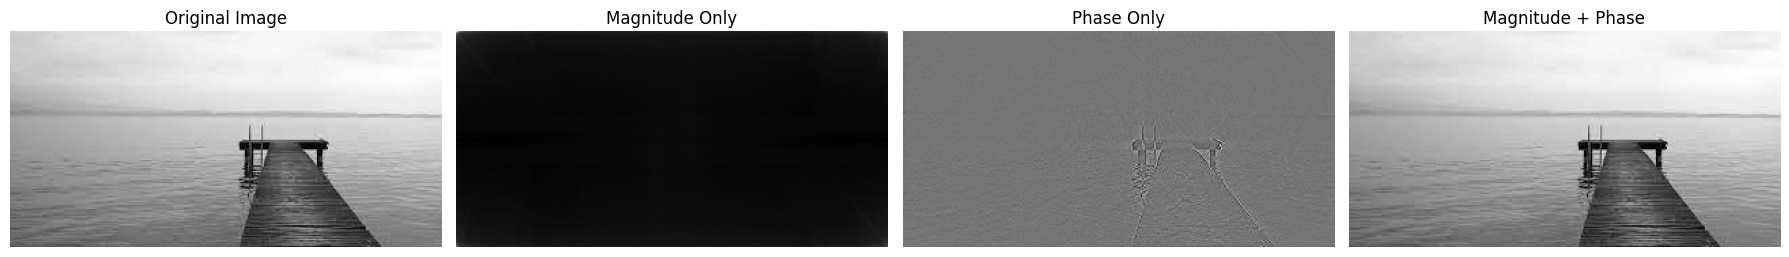

Maximum reconstruction error: 1.1102230246251565e-15


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load grayscale image using OpenCV
img = cv2.imread("./images.jpeg", cv2.IMREAD_GRAYSCALE)



# Normalize pixel values
img = img.astype(np.float64) / 255.0

print("Image shape:", img.shape)

F = np.fft.fft2(img)

magnitude = np.abs(F)
phase = np.angle(F)


F_mag = magnitude * np.exp(1j * 0)
recon_mag = np.fft.ifft2(F_mag).real


F_phase = np.exp(1j * phase)
recon_phase = np.fft.ifft2(F_phase).real


F_both = magnitude * np.exp(1j * phase)
recon_both = np.fft.ifft2(F_both).real

 
fig, ax = plt.subplots(1, 4, figsize=(18, 5))

images = [
    img,
    recon_mag,
    recon_phase,
    recon_both
]

titles = [
    "Original Image",
    "Magnitude Only",
    "Phase Only",
    "Magnitude + Phase"
]

for i in range(4):
    ax[i].imshow(images[i], cmap="gray")
    ax[i].set_title(titles[i])
    ax[i].axis("off")

plt.tight_layout()
plt.show()

# 8. Calculate reconstruction error
error = np.max(np.abs(img - recon_both))

print("Maximum reconstruction error:", error)